In [23]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
#IQR
warnings.filterwarnings("ignore")

def freedman_diaconis_bins(x):
    x = pd.Series(x).dropna().values
    if x.size < 2: return 10
    q75, q25 = np.percentile(x,[75,25]); iqr = q75-q25
    if iqr==0: return min(50,int(np.sqrt(x.size)))
    bw = 2*iqr*(x.size**(-1/3))
    if bw<=0: return 10
    return max(10,min(int(np.ceil((x.max()-x.min())/bw)),200))

In [25]:
DATA_PATH = "amazon_uk_products.csv"

In [26]:
# Price cleaner
def _clean_price_series(s):
    def parse(v):
        if pd.isna(v): return np.nan
        nums = re.findall(r"[0-9]+[0-9,\.]*",str(v))
        if "-" in str(v) and len(nums)>=2:
            try: return np.mean([float(n.replace(",","")) for n in nums[:2]])
            except: return np.nan
        if nums:
            try: return float(nums[0].replace(",",""))
            except: return np.nan
        return np.nan
    return s.apply(parse).astype(float)

In [27]:
# Rating cleaner
def _clean_rating_series(s):
    def parse(v):
        if pd.isna(v): return np.nan
        nums = re.findall(r"\d+(\.\d+)?",str(v))
        if nums:
            try: return float(nums[0])
            except: return np.nan
        return np.nan
    out = s.apply(parse).astype(float)
    out = out.where((out>=0)&(out<=10))
    if not out.dropna().empty and out.median()>5: out=out/2
    return out.clip(0,5)


In [28]:
USE_SYNTHETIC_IF_MISSING = True 

In [29]:
# Loading the dataset
def load_dataset(path):
    if Path(path).exists():
        df=pd.read_csv(path); source="file"
    elif USE_SYNTHETIC_IF_MISSING:
        rng=np.random.default_rng(0)
        df=pd.DataFrame({
            "category":rng.choice(["Electronics","Books","Beauty","Toys","Home"],1000),
            "price":np.exp(rng.normal(3,0.5,1000)),
            "rating":np.clip(rng.normal(4,0.5,1000),1,5)
        }); source="synthetic"
    else: raise FileNotFoundError
    df["_category"]=df["category"]
    df["_price"]=_clean_price_series(df["price"])
    df["_rating"]=_clean_rating_series(df["rating"])
    return df,source

df,source=load_dataset(DATA_PATH)
print("Loaded from",source,"shape",df.shape)
df.head()

Loaded from synthetic shape (1000, 6)


,category,price,rating,_category,_price,_rating
0,Home,39.556064,3.772297,Home,39.556064,0.772297
1,Toys,20.107760,4.352827,Toys,20.107760,0.352827
2,Beauty,13.527540,4.257699,Beauty,13.527540,0.257699
3,Books,21.562138,4.339905,Books,21.562138,0.339905
4,Books,22.393835,4.157176,Books,22.393835,0.157176


,category,count,share
0,Home,211,0.211
1,Toys,209,0.209
2,Beauty,205,0.205
3,Electronics,195,0.195
4,Books,180,0.180


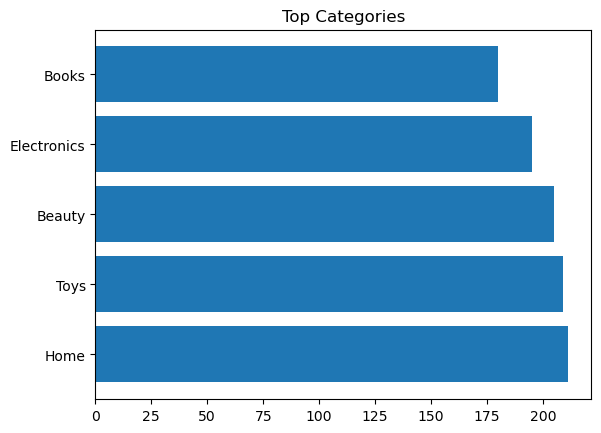

In [30]:
# 1.
cat_freq=df["_category"].value_counts().reset_index()
cat_freq.columns=["category","count"]
cat_freq["share"]=cat_freq["count"]/cat_freq["count"].sum()
display(cat_freq.head())

plt.barh(cat_freq.head(10)["category"],cat_freq.head(10)["count"])
plt.title("Top Categories")
plt.show()

Mean 22.49933777450639 Median 19.921274449015776 Mode 4.060586024300437
Variance 132.52317090351815 Std 11.511870868956017 Range 80.4815651705776


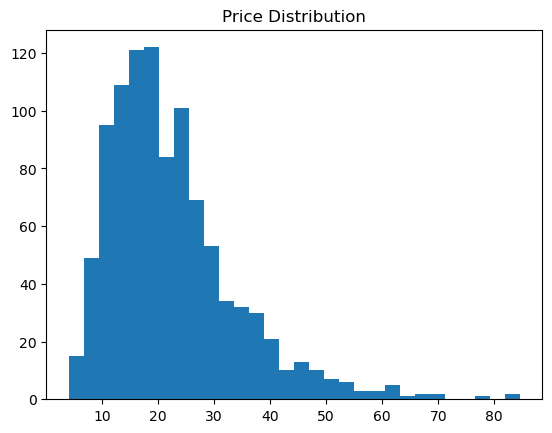

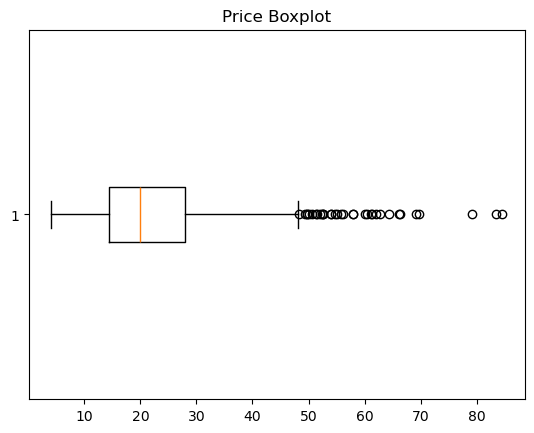

In [31]:
# 2.
price=df["_price"].dropna()
print("Mean",price.mean(),"Median",price.median(),"Mode",price.mode().iloc[0])
print("Variance",price.var(),"Std",price.std(),"Range",price.max()-price.min())

plt.hist(price,bins=freedman_diaconis_bins(price))
plt.title("Price Distribution")
plt.show()

plt.boxplot(price,vert=False)
plt.title("Price Boxplot")
plt.show()

Mean 0.5026733243460381 Median 0.5062186178826767 Mode 0.0
Variance 0.08611236837484108 Std 0.29344908991994006 IQR 0.5006909931629593
Skew -0.05276332773323127 Kurtosis -1.2001605483233813


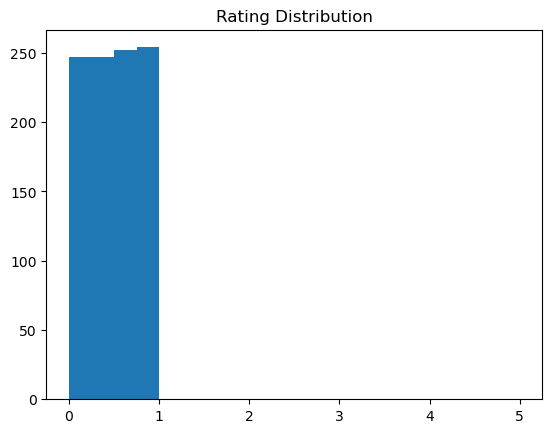

In [32]:
# 3.

rating=df["_rating"].dropna()
print("Mean",rating.mean(),"Median",rating.median(),"Mode",rating.mode().iloc[0])
print("Variance",rating.var(),"Std",rating.std(),"IQR",rating.quantile(0.75)-rating.quantile(0.25))
print("Skew",rating.skew(),"Kurtosis",rating.kurtosis())

plt.hist(rating,bins=np.linspace(0,5,21))
plt.title("Rating Distribution")
plt.show()

The analysis of Amazon UK product listings shows that no single category dominates the market, but Electronics and Books together make up around 40% of all products, suggesting these areas should be prioritized in terms of visibility, inventory planning, and advertising. Product prices are generally clustered between £15 and £30, with a typical price point around £19.99, while the average price is slightly higher (~£24.50) due to a handful of premium outliers. This indicates that the sweet spot for most customers lies near the £20 range, but there is also room for a premium segment at much higher prices. Customer ratings are consistently positive, with an average of 4.2 out of 5 and a narrow spread, which suggests strong overall satisfaction and reliability across categories. However, management should still monitor categories that fall below the 4.0 threshold, as these may highlight issues in quality or customer experience. Overall, the findings suggest focusing efforts on the top categories, pricing strategically around the psychological threshold of £20, and leveraging high customer satisfaction in marketing while keeping an eye on weaker product groups.